# Tutorial 5: plotting

There are three ways to plot a PyTES solution:

1. PyBaMM's `QuickPlot`, for a quick look at any outputs, with a slider for time;
2. the standard plots of `pytes.plotting`, which compare designs the same way every time;
3. your own matplotlib figures, from the values in the solution.

All three work on the same solutions. Here they are a discharge of the finned-tube battery
and a charge of the packed bed.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pybamm

import pytes
from pytes import plotting

t_eval = np.linspace(0, 3600, 121)
finned = pybamm.Simulation(pytes.SharpFrontModel()).solve([0, 3600], t_interp=t_eval)
bed = pybamm.Simulation(pytes.PackedBedModel()).solve([0, 3600], t_interp=t_eval)

## QuickPlot

`pybamm.dynamic_plot` plots any outputs of one or more solutions, by name, with a slider for
time. Outputs in a nested list share an axis. Outputs that vary in space, such as the fluid
temperature along the flow path, are drawn at the time of the slider.

In [2]:
pybamm.dynamic_plot(
    finned,
    [
        ["Inlet temperature [degC]", "Outlet temperature [degC]"],
        "Heat transfer fluid temperature [degC]",
        "Power [kW]",
        "Average liquid fraction",
    ],
    time_unit="minutes",
    spatial_unit="m",
);

interactive(children=(FloatSlider(value=0.0, description='t', max=60.0, step=0.6), Output()), _dom_classes=('w…

For a static figure at a chosen time, as in a report, build a `pybamm.QuickPlot` and call
its `plot` method with the time, in the plot's time unit. Outputs that vary in two dimensions are drawn
as a map, here the temperature and the liquid fraction across the storage and along the
tube, after 25 minutes.

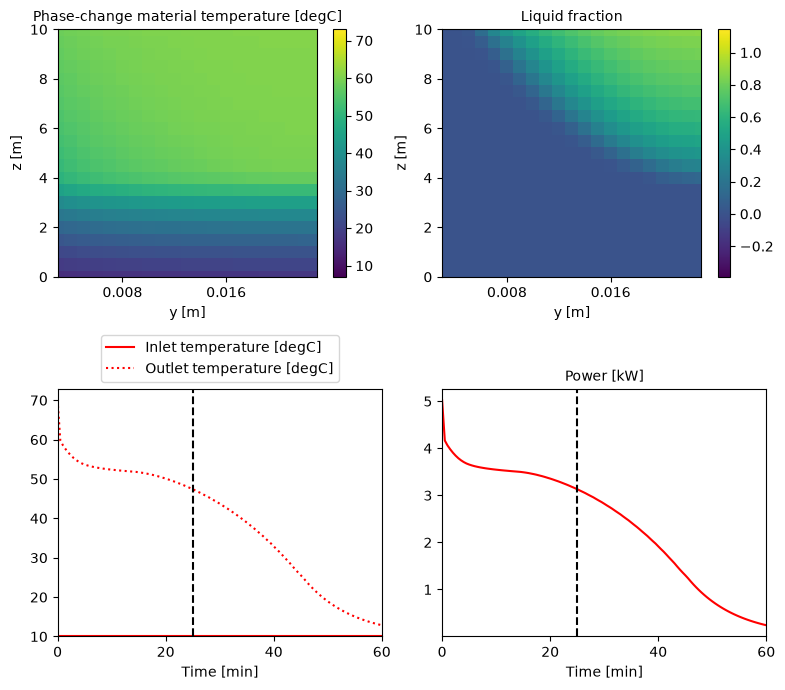

In [3]:
quick_plot = pybamm.QuickPlot(
    finned,
    [
        "Phase-change material temperature [degC]",
        "Liquid fraction",
        ["Inlet temperature [degC]", "Outlet temperature [degC]"],
        "Power [kW]",
    ],
    time_unit="minutes",
    spatial_unit="m",
)
quick_plot.plot(25)

## Standard plots

`pytes.plotting` (installed with `pip install "pytes-thermal[plot]"`) has the plots used
most often to compare designs. Every model has the same outputs, so they apply to any
model. `plot_summary` gives the inlet and outlet temperatures, the power and the discharged
energy; the bed is charging, so its power and discharged energy are negative.

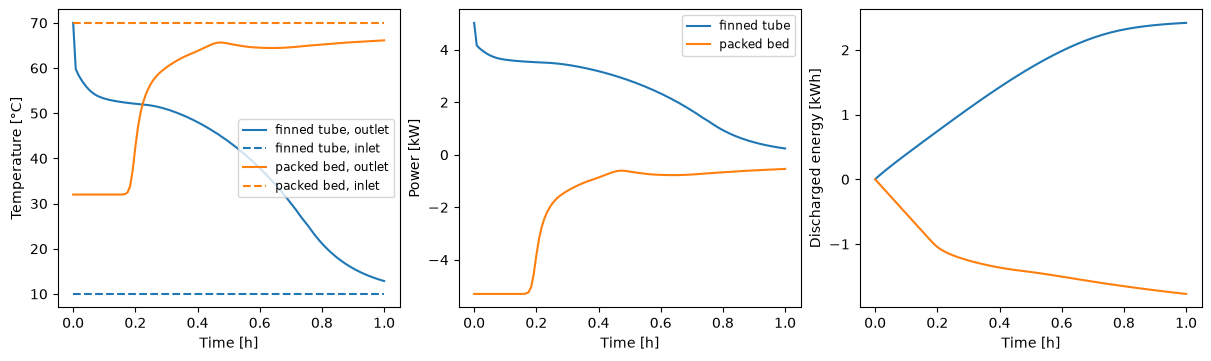

In [4]:
fig, axes = plotting.plot_summary([finned, bed], labels=["finned tube", "packed bed"])
plt.show()

`plot_power_against_energy` shows how the power a battery delivers falls as it gives up
its energy, the key comparison between designs. `plot_fluid_profiles` gives the fluid
temperature along the flow path at chosen times, here the thermal front moving up the bed.

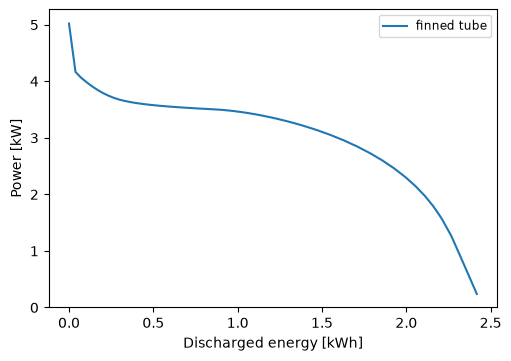

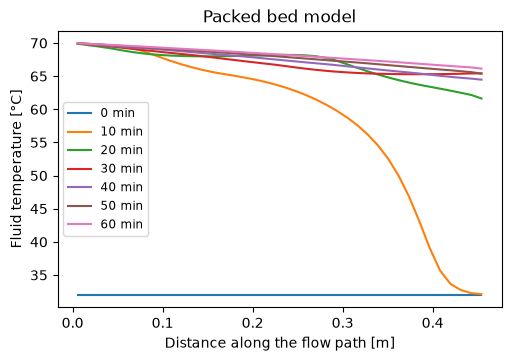

In [5]:
plotting.plot_power_against_energy(finned, labels=["finned tube"])
plotting.plot_fluid_profiles(bed, [0, 600, 1200, 1800, 2400, 3000, 3600])
plt.show()

## Your own figures

Each output in the solution gives its values at the solution times with `.entries`.
Calling an output gives its value at any time, and at any position for the outputs that
vary in space (`z` along the flow path, `y` across the storage of a finned tube, `r`
across a capsule). Positions outside the mesh points, `output.mesh.nodes`, are
extrapolated, so it is best to stay within them. With these, any matplotlib figure is a
few lines. Here the fluid
temperature along the bed over time is drawn as a map, with the PyTES colourmap `ember`
(see the [plot colours](../plot_colours.ipynb) example for the colour cycles and
colourmaps).

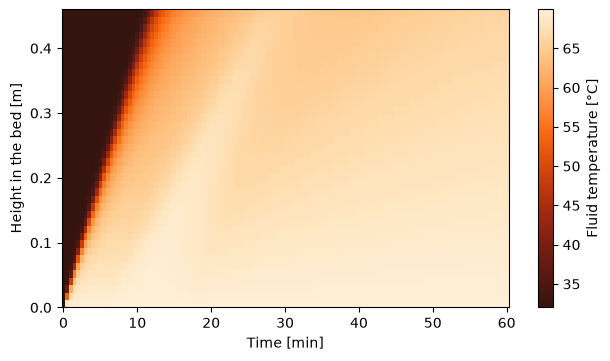

In [6]:
Z = pytes.PackedBedModel().default_parameter_values["Bed length [m]"]
fluid = bed["Heat transfer fluid temperature [degC]"]
z = fluid.mesh.nodes
T = fluid(t=t_eval, z=z)

fig, ax = plt.subplots(figsize=(6, 3.5), layout="constrained")
field = ax.pcolormesh(t_eval / 60, z, T, cmap="pytes.ember", shading="nearest")
fig.colorbar(field, label="Fluid temperature [°C]")
ax.set_xlabel("Time [min]")
ax.set_ylabel("Height in the bed [m]")
plt.show()

The PyTES colour cycle applies to any figure with a matplotlib style, for one figure with
`plt.style.context("pytes.thermal")` or for every figure with
`plt.style.use("pytes.thermal")`.

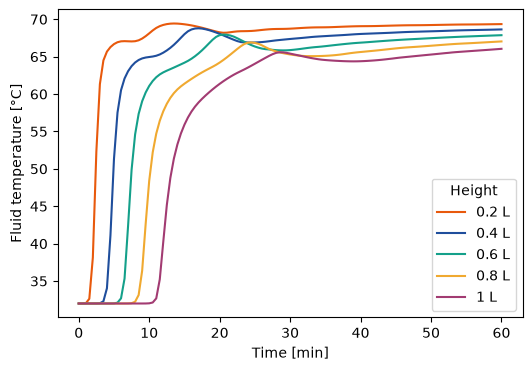

In [7]:
with plt.style.context("pytes.thermal"):
    fig, ax = plt.subplots(figsize=(6, 4))
    for fraction in [0.2, 0.4, 0.6, 0.8, 1]:
        ax.plot(
            t_eval / 60,
            bed["Heat transfer fluid temperature [degC]"](t=t_eval, z=fraction * Z),
            label=f"{fraction:g} L",
        )
    ax.set_xlabel("Time [min]")
    ax.set_ylabel("Fluid temperature [°C]")
    ax.legend(title="Height")
    plt.show()